# Final holdout evaluation (April 2016 - September 2026)

Runs the **frozen** strategy in `config/frozen_strategy.json` exactly once. `authorize_final` checks the SHA-256 lock, refuses a different config, and appends this run to `results/final_runs.jsonl`. Small result tables and the chart go to `results/` (committed); per-trade tables to `outputs/final/` (ignored).

In [1]:
acknowledge_reselection = False
note = "final evaluation"

In [2]:
# Parameters
acknowledge_reselection = False
note = "re-run of the same frozen config to add the settle-at-maturity accounting sensitivity (frozen lots = 55% of NAV)"


In [3]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'quantlab').is_dir())
sys.path.insert(0, str(root))
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from quantlab import protocol
from quantlab.experiment import run_final
cfg = json.loads(protocol.FROZEN_CONFIG.read_text())
auth = protocol.authorize_final(cfg, acknowledge_reselection=acknowledge_reselection, note=note)
print(auth.config_sha256, 'prior final runs:', auth.prior_final_runs)

c9c17242ae8513eb69c7313ee3ba42f2d5b3f6f675865e4d9b1b7756cad57485 prior final runs: 1


In [4]:
fin = run_final(cfg, auth)
print(json.dumps(fin['summary'], indent=1, default=str))

[prepare:final] 2,071,060 panel rows, 1,795,256 eligible, 33s


{
 "experiment_id": "B2_inverse_vol-c9c17242",
 "mode": "final",
 "config_sha256": "c9c17242ae8513eb69c7313ee3ba42f2d5b3f6f675865e4d9b1b7756cad57485",
 "authorized_at": "2026-11-13T05:06:33+00:00",
 "prior_final_runs": 1,
 "reselection_acknowledged": false,
 "test_window": "2016-04-01 .. 2026-09-30",
 "final_value": 2507699.8229169836,
 "benchmark_final_value": 4402746.776270891,
 "excess_final_value": -1895046.953353907,
 "beat_benchmark": false,
 "CAGR": 0.09150940518288841,
 "benchmark_CAGR": 0.1516195212753213,
 "Sharpe": 0.56344373449118,
 "benchmark_Sharpe": 0.772500797137751,
 "max_drawdown": -0.3249294116194579,
 "benchmark_max_drawdown": -0.3379046158626988,
 "test_mean_rank_IC": 0.03589989603534879,
 "audit_checks_passed": "17/17",
 "integrity_events_in_test": {
  "unclassified": 1861,
  "bad_print": 585,
  "split": 128,
  "level_shift": 57
 },
 "integrity_events_touching_held_lots": {
  "unclassified": 12,
  "bad_print": 8,
  "split": 4
 },
 "warnings": [
  "171 lots frozen 

## Required comparison: strategy vs $1,000,000 in ^SP500TR at the first test close

,strategy,S&P 500 TR
start,2016-03-31,2016-03-31
end,2026-09-30,2026-09-30
final_value,2507699.822917,4402746.776271
total_return,1.5077,3.402747
CAGR,0.091509,0.15162
max_drawdown,-0.324929,-0.337905
max_drawdown_date,2020-03-23,2020-03-23
annualized_volatility,0.137527,0.178178
Sharpe,0.563444,0.772501


beta                 0.652
tracking_error       0.096
information_ratio   -0.625
correlation          0.845
dtype: float64

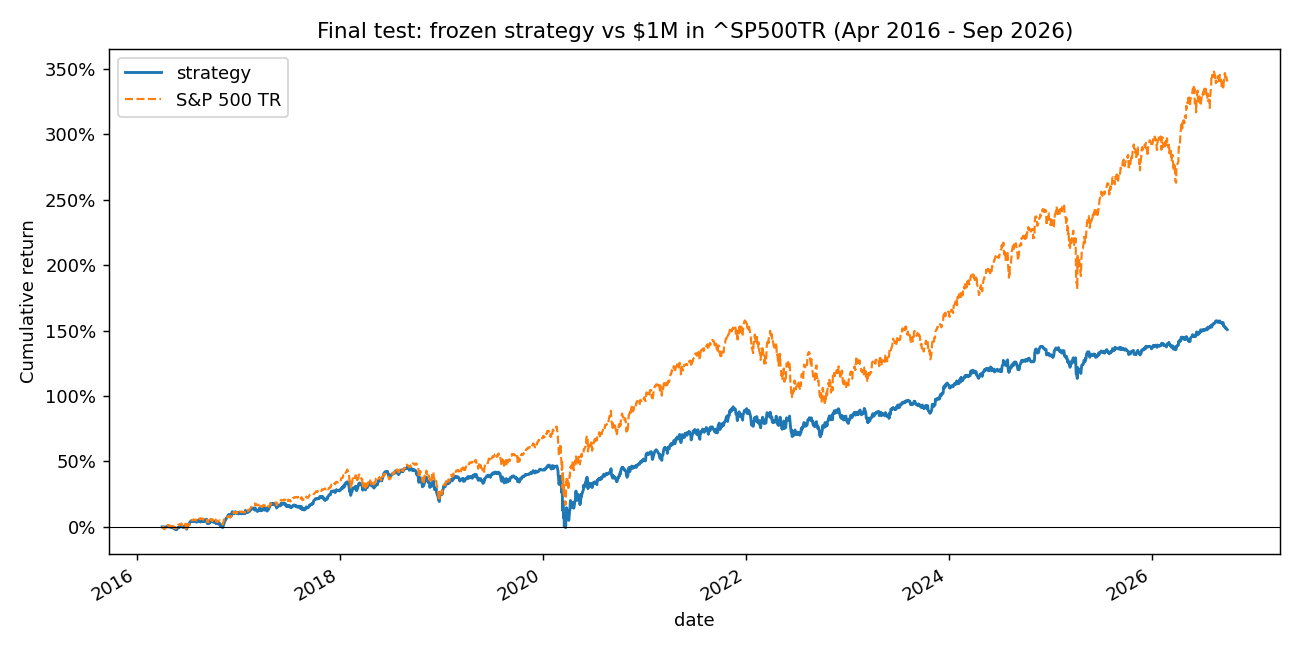

In [5]:
display(fin['performance'])
display(fin['relative'].round(3))
display(Image(filename=str(root / 'results' / 'cumulative_return.png')))

## Accounting and timing audit of the final run

In [6]:
display(fin['audit'])
assert fin['audit'].passed.all()

,check,passed,detail
0,cash = initial + cumulative fill cash changes,True,max abs error 3.89e-09
1,cash never negative,True,min cash 33937.800131
2,nav = cash + holdings,True,
3,holdings = units x last observed quote (indepe...,True,max abs error 3.73e-09
4,units never negative,True,
5,every buy fills on the session after its signal,True,violations 0
6,buy price = that session's close,True,
7,same-day buys <= cash at the signal close (no ...,True,
8,fees = notional x fee rate,True,
9,due date = entry + holding period,True,


## Sensitivity: data repairs, frozen-lot write-off, and costs

In [7]:
display(fin['sensitivity'][['final_value','CAGR','max_drawdown','Sharpe']])

,final_value,CAGR,max_drawdown,Sharpe
"primary (repaired prices, 5 bps)",2507699.822917,0.091509,-0.324929,0.563444
frozen lots written to zero (lower bound),1120013.393143,0.010853,-0.381648,0.045645
prices as delivered (no split/level repair),2641524.519574,0.096928,-0.324643,0.596007
all breaks neutralized,2511340.808091,0.09166,-0.324932,0.564496
frozen lots settled at maturity at last mark (cash recycled),3538640.413333,0.127903,-0.354598,0.684023
fees 0 bps,2588509.8269,0.094812,-0.324885,0.584793
fees 25 bps,2210913.01142,0.078493,-0.329007,0.478064


## Prediction quality on completed test labels

In [8]:
display(fin['prediction'])
display(fin['prediction_by_year'].round(4))

dates                      603.000000
mean_rank_IC                 0.035900
IC_std                       0.135050
IC_hit_rate                  0.618574
IC_tstat_blocks              2.374342
top_minus_bottom_decile      0.008637
dtype: float64

,dates,mean_rank_IC,IC_std,IC_hit_rate,IC_tstat_blocks,top_minus_bottom_decile
year,,,,,,
2016,45.0,-0.0610,0.1056,0.3111,-0.8084,-0.0234
2017,59.0,0.0439,0.0525,0.7797,2.9835,0.0086
2018,59.0,0.0333,0.0721,0.6441,1.0210,0.0172
2019,59.0,0.0595,0.0929,0.7458,2.2659,0.0192
2020,59.0,-0.1009,0.1631,0.3729,-1.8155,-0.1009
2021,57.0,0.1812,0.0907,0.9825,6.1946,0.1477
2022,60.0,0.1105,0.1579,0.6833,1.8894,0.0667
2023,59.0,0.0798,0.1235,0.6949,1.8822,0.0238
2024,59.0,0.0235,0.1053,0.5424,0.7532,0.0044


## Portfolio diagnostics and data incidents touching held lots

In [9]:
display(fin['diagnostics'].round(4))
display(fin['touched'].groupby('kind').size())
display(fin['touched'].sort_values('date').head(30))

average_cash_fraction            0.0671
fees                         47621.7394
turnover_x_avg_nav              28.0666
lots_opened                  16316.0000
lots_closed                  15755.0000
lot_win_rate                     0.5704
mean_lot_net_return              0.0405
open_lots_at_end               561.0000
frozen_lots_at_end             171.0000
max_frozen_value_fraction        0.5629
rejected_orders                  5.0000
avg_names_held_proxy           442.7830
dtype: float64

kind
bad_print        8
split            4
unclassified    12
dtype: int64

,symbol,date,prev_date,confirm_date,gross,pre_price,post_price,pre_close,dv_day_ratio,kind,ratio,segment_quotes,lot_id,entry_date,exit_date,units,state
1491,KDP,2018-07-10,2018-07-09,2018-07-17,6.924460,2.78,19.25,19.91,1.528634,split,7.000000,0,3401,2018-06-11,2018-09-10,579.897002,closed
2460,TE,2020-01-10,2016-06-30,2020-01-17,0.355282,27.64,9.82,27.64,NaN,unclassified,NaN,0,269,2016-06-06,NaT,509.148573,open
2461,TE,2020-01-10,2016-06-30,2020-01-17,0.355282,27.64,9.82,27.64,NaN,unclassified,NaN,0,290,2016-06-13,NaT,508.314937,open
2462,TE,2020-01-10,2016-06-30,2020-01-17,0.355282,27.64,9.82,27.64,NaN,unclassified,NaN,0,320,2016-06-20,NaT,519.720492,open
1827,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.38,2.39,4.58,0.898756,bad_print,NaN,1,6076,2020-03-02,2020-06-01,275.483282,closed
1826,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.38,2.39,4.58,0.898756,bad_print,NaN,1,6034,2020-02-18,2020-05-18,269.319443,closed
1825,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.38,2.39,4.58,0.898756,bad_print,NaN,1,5953,2020-02-03,2020-05-04,209.991915,closed
1824,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.38,2.39,4.58,0.898756,bad_print,NaN,1,5921,2020-01-27,2020-04-27,195.061573,closed
1821,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.38,2.39,4.58,0.898756,bad_print,NaN,1,5842,2020-01-06,2020-04-06,191.032068,closed
1823,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.38,2.39,4.58,0.898756,bad_print,NaN,1,5895,2020-01-21,2020-04-20,187.120064,closed
